In [14]:
import pandas as pd
import numpy as np
from doepy import build, read_write
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt

"""
# Read variables and levels from CSV file
variables_df = pd.read_csv('VolTestFDOPA.csv')
print(variables_df)

# Convert DataFrame to dictionary
variables = variables_df.to_dict(orient='list')

# Create a Central Composite Design (CCD)
ccd_design = build.central_composite(variables)
print(ccd_design)
"""

read_write.write_csv(
build.central_composite(read_write.read_variables_csv('VolTestFDOPA.csv'),),
filename='DOE_table.csv'
)


In [15]:
"""
# Simulated response data (replace this with actual experimental data)
df = pd.read_csv('DOE_table-2.csv')
ccd_design['RCC'] = df['RCC']
print(ccd_design)

# Fit a second-order polynomial model
model = ols('RCC ~ Pre + Cu + Bu + Pyr + I(Pre**2) + I(Cu**2) + I(Bu**2) + + I(Pyr**2) + Pre:Cu + Pre:Bu + Pre:Pyr + Cu:Bu + Cu:Pyr + Bu:Pyr + Bu:Res', data=ccd_design).fit()
print(model.summary())
"""

"\n# Simulated response data (replace this with actual experimental data)\ndf = pd.read_csv('DOE_table-2.csv')\nccd_design['RCC'] = df['RCC']\nprint(ccd_design)\n\n# Fit a second-order polynomial model\nmodel = ols('RCC ~ Pre + Cu + Bu + Pyr + I(Pre**2) + I(Cu**2) + I(Bu**2) + + I(Pyr**2) + Pre:Cu + Pre:Bu + Pre:Pyr + Cu:Bu + Cu:Pyr + Bu:Pyr + Bu:Res', data=ccd_design).fit()\nprint(model.summary())\n"

In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

data = pd.read_csv('DOE_table-2.csv')

# Extract features and target variable
X = data[['Pre', 'Cu', 'Bu', 'Pyr']].values  # Replace with your feature columns
y = data['RCC'].values  # Replace with your target column

# Create polynomial features
poly = PolynomialFeatures(degree=2)  # Change the degree if needed
X_poly = poly.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)

# Create and fit the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [17]:
from sklearn.metrics import mean_squared_error, r2_score

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

Mean Squared Error: 2424.683467044954
R^2 Score: -1.1221497926104127


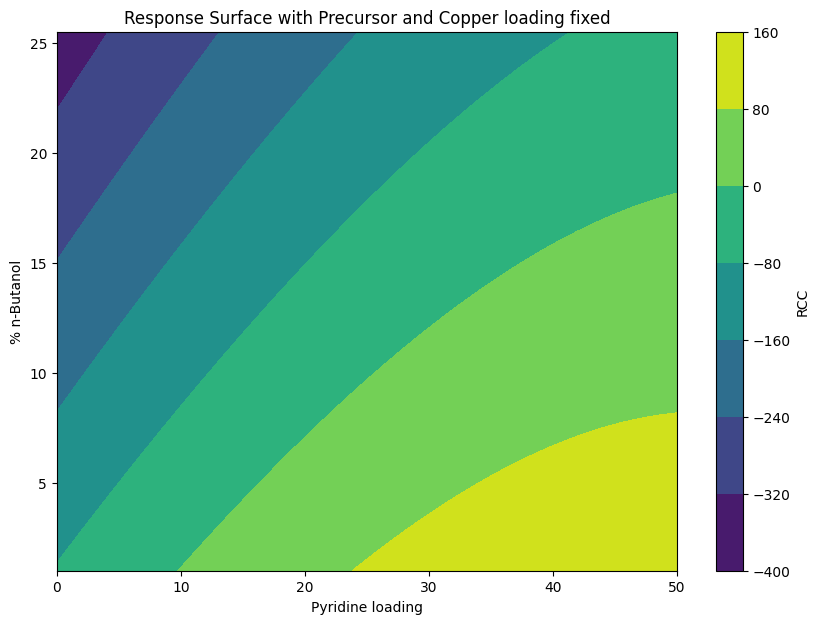

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Define fixed values for other features
fixed_feature1 = 1.0
fixed_feature2 = 2.0

# Create a mesh grid for the variable features
feature3_range = np.linspace(X[:, 2].min(), X[:, 2].max(), 100)
feature4_range = np.linspace(X[:, 3].min(), X[:, 3].max(), 100)
feature3_grid, feature4_grid = np.meshgrid(feature3_range, feature4_range)
grid_points = np.column_stack([
    np.full(feature3_grid.size, fixed_feature1),
    np.full(feature3_grid.size, fixed_feature2),
    feature3_grid.ravel(),
    feature4_grid.ravel()
])

# Transform and predict
grid_points_poly = poly.transform(grid_points)
y_grid = model.predict(grid_points_poly)
y_grid = y_grid.reshape(feature4_grid.shape)

# Plot
plt.figure(figsize=(10, 7))
plt.contourf(feature3_grid, feature4_grid, y_grid, cmap='viridis')
plt.colorbar(label='RCC')
plt.xlabel('Pyridine loading')
plt.ylabel('% n-Butanol')
plt.title('Response Surface with Precursor and Copper loading fixed')
plt.show()


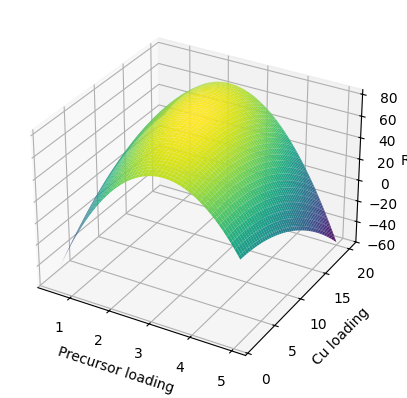

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create a mesh grid for the features
x1_range = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
x2_range = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)
x_grid = np.column_stack([x1_grid.ravel(), x2_grid.ravel()])
x_grid_poly = poly.transform(x_grid)

# Predict over the grid
y_grid = model.predict(x_grid_poly)
y_grid = y_grid.reshape(x1_grid.shape)

# Plot the response surface
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1_grid, x2_grid, y_grid, cmap='viridis')

ax.set_xlabel('Precursor loading')
ax.set_ylabel('Cu loading')
ax.set_zlabel('RCC')
plt.show()
